# Example of the aitlas toolbox in the context of multi class image classification

## Import the required packages

In [ ]:
from aitlas.datasets import RSICB128Dataset
from aitlas.models import VisionTransformer
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor, ResizeRandomCropFlipHVToTensor
from aitlas.utils import image_loader

## Load the dataset

In [9]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/RSI-CB128/",
    "csv_file": "/home/dragik/data/FAIR_EO/RSI-CB128/train.csv",
    "batch_size": 128,
    "shuffle": True,
    "num_workers": 4,
}
dataset = RSICB128Dataset(dataset_config)

## Show images from the dataset

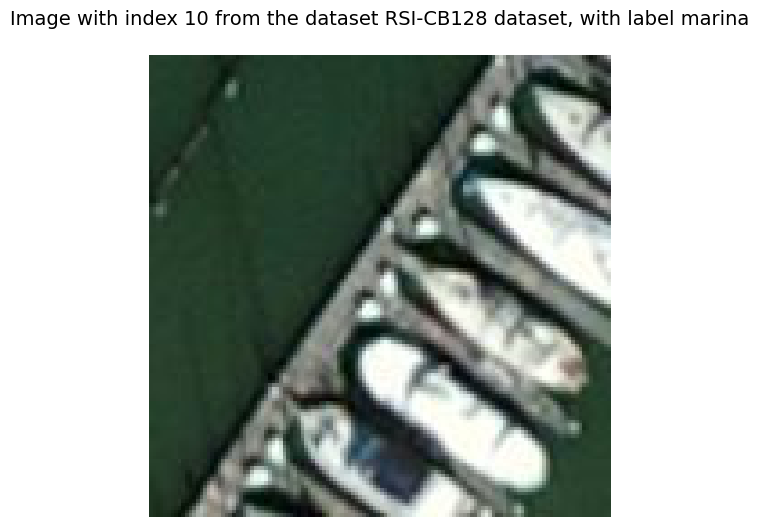

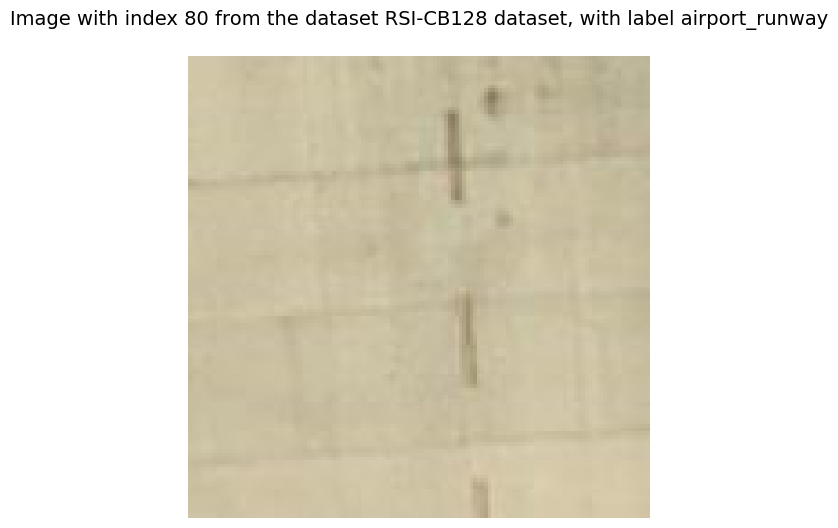

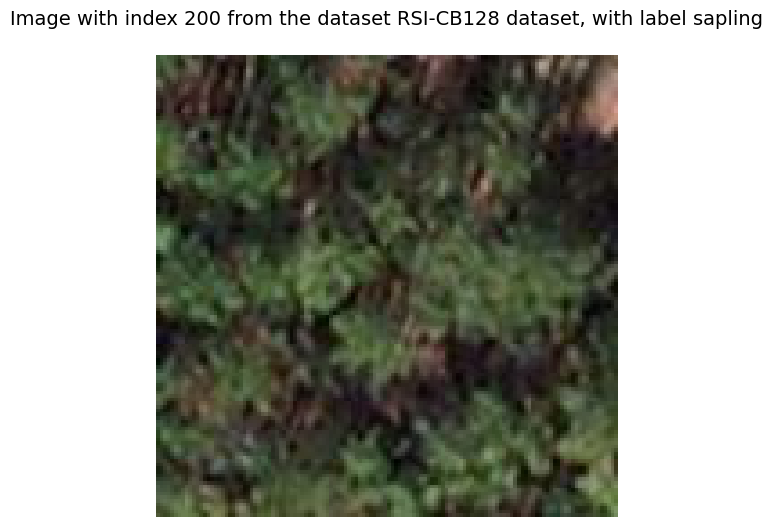

In [10]:
fig1 = dataset.show_image(10)
fig2 = dataset.show_image(80)
fig3 = dataset.show_image(200)

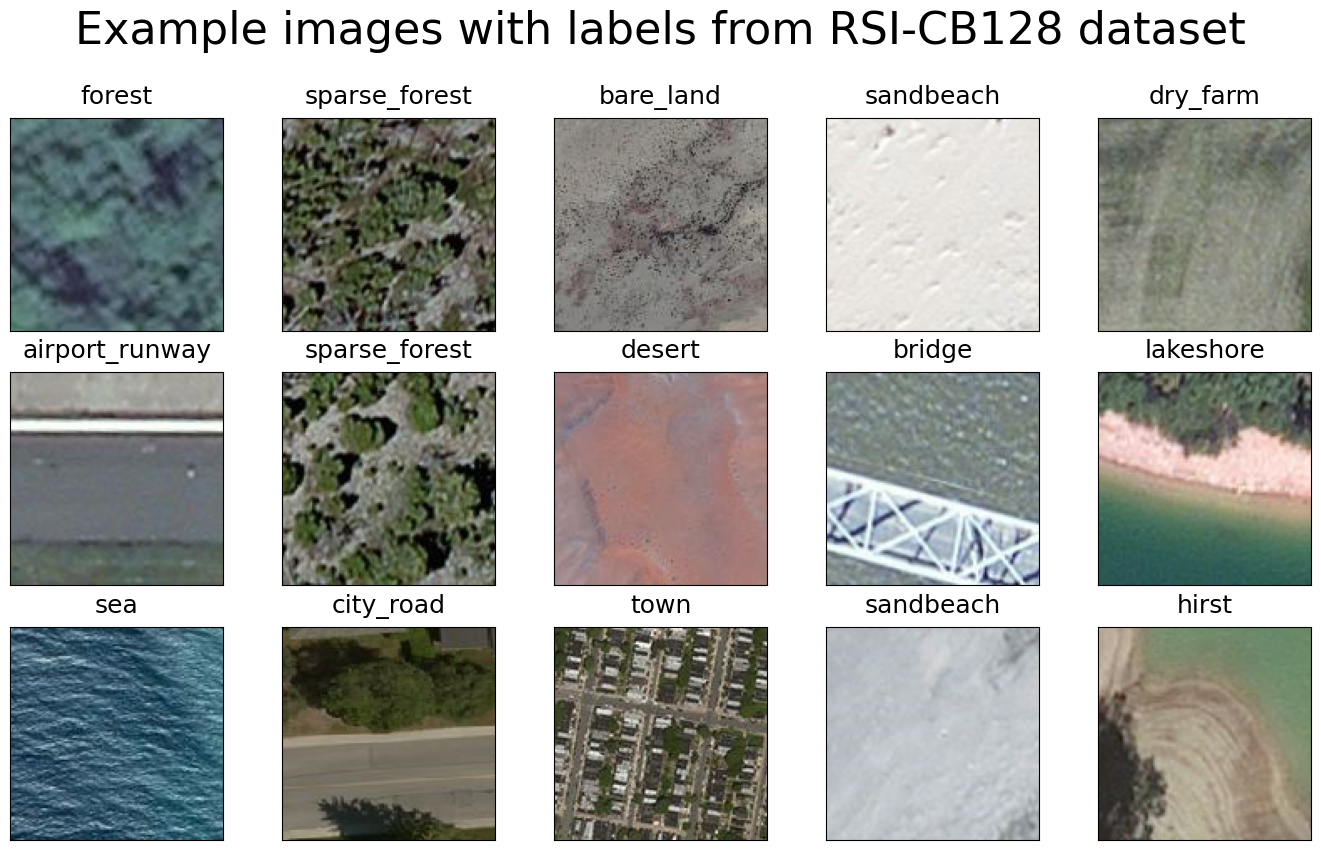

In [11]:
fig4 = dataset.show_batch(15)

## Inspect the data

In [12]:
dataset.show_samples()

,File name,Label
0,mountain/mountain(717).tif,mountain
1,shrubwood/shrubwood(699).tif,shrubwood
2,forest/forest(708).tif,forest
3,container/container(953).tif,container
4,town/town(485).tif,town
5,sparse_forest/sparse_forest(1346).tif,sparse_forest
6,residents/residents(204).tif,residents
7,city_green_tree/city_green_tree(78).tif,city_green_tree
8,sparse_forest/sparse_forest(1208).tif,sparse_forest
9,dry_farm/dry_farm(149).tif,dry_farm


In [13]:
dataset.data_distribution_table()

,Label,Count
0,airport_runway,938
1,artificial_grassland,288
2,avenue,465
3,bare_land,921
4,bridge,339
5,city_avenue,370
6,city_building,838
7,city_green_tree,332
8,city_road,281
9,coastline,534


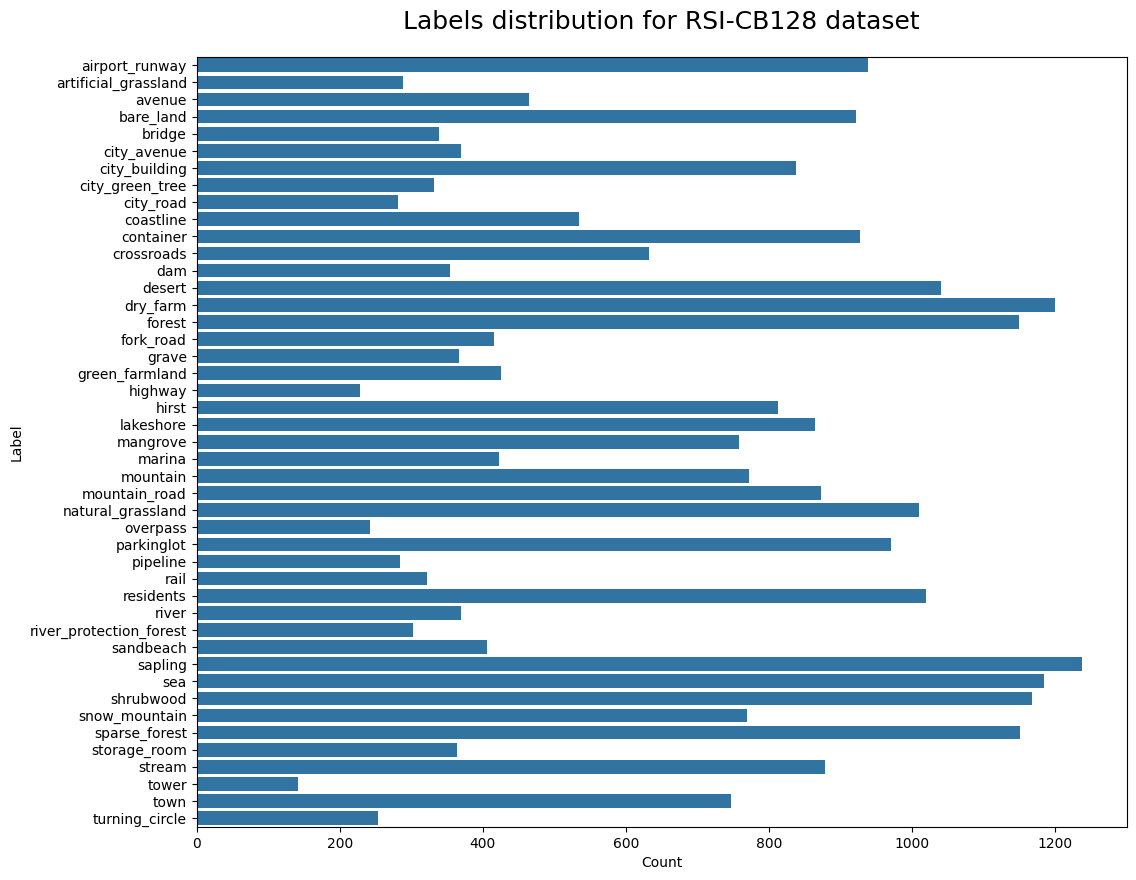

In [14]:
fig = dataset.data_distribution_barchart()

## Load train and validation splits

In [4]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/RSI-CB128/",
    "csv_file": "/home/dragik/data/FAIR_EO/RSI-CB128/train.csv",
}

train_dataset = RSICB128Dataset(train_dataset_config)
train_dataset.transform = ResizeRandomCropFlipHVToTensor() 

validation_dataset_config = {
    "batch_size": 32,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/RSI-CB128/",
    "csv_file": "/home/dragik/data/FAIR_EO/RSI-CB128/val.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

validation_dataset = RSICB128Dataset(validation_dataset_config)
len(train_dataset), len(validation_dataset)

(29367, 3670)

## Setup and create the model for training

In [5]:
epochs = 20
model_directory = "/home/dragik/data/FAIR_EO/experiments/RSI-CB128/"
model_config = {
    "num_classes": 45, 
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"]
}
model = VisionTransformer(model_config)
model.prepare()

2025-05-13 06:51:16,277 INFO Loading pretrained weights from Hugging Face hub (timm/vit_base_patch16_224.augreg2_in21k_ft_in1k)
2025-05-13 06:51:16,454 INFO [timm/vit_base_patch16_224.augreg2_in21k_ft_in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.


## Training and validation

In [6]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=validation_dataset,
    run_id='1',
)

2025-05-13 06:51:18,787 INFO Starting training.
training: 100%|██████████| 918/918 [09:18<00:00,  1.65it/s]
2025-05-13 07:00:37,130 INFO epoch: 1, time: 558, loss:  0.31461
testing on train set: 100%|██████████| 918/918 [03:23<00:00,  4.52it/s]
2025-05-13 07:04:02,579 INFO Accuracy:0.9722477610923826, Precision Micro:0.9722477610923826, Precision Macro:0.9620290511575852, Precision Weighted:0.974772393871244, Precision per Class:[0.94193548 0.98606272 0.94834711 0.97823597 0.89304813 0.97354497
 0.97491039 1.         0.90625    0.97605893 1.         0.99189627
 0.92753623 0.97469541 0.97073579 0.99824253 0.95399516 0.99182561
 1.         0.7015873  0.99632353 1.         0.99604743 0.99526066
 1.         0.98085586 1.         0.88416988 0.99278351 0.98245614
 0.93134328 0.99787234 0.97245179 0.996633   0.7822736  0.9983871
 0.98811545 1.         0.99350649 1.         0.99726027 0.89581205
 1.         1.         0.82084691], Recall Micro:0.9722477610923826, Recall Macro:0.968517016748278

0.0020575020374292157

## Test the model

In [7]:

test_dataset_config = {
    "batch_size": 16,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/RSI-CB128/",
    "csv_file": "/home/dragik/data/FAIR_EO/RSI-CB128/test.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

test_dataset = RSICB128Dataset(test_dataset_config)
model_path = "/home/dragik/data/FAIR_EO/experiments/RSI-CB128/checkpoint.pth.tar"
model.metrics = ["accuracy", "precision", "recall", "f1_score"]
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

2025-05-13 10:44:45,933 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/RSI-CB128/checkpoint.pth.tar
2025-05-13 10:44:46,307 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/RSI-CB128/checkpoint.pth.tar at epoch 21
testing on test set: 100%|██████████| 230/230 [00:11<00:00, 20.52it/s]


[{'Accuracy': 0.9953678474114441},
 {'Precision Micro': 0.9953678474114441,
  'Precision Macro': 0.9924396005006606,
  'Precision Weighted': 0.9953964369128291,
  'Precision per Class': array([1.        , 1.        , 1.        , 1.        , 1.        ,
         1.        , 1.        , 1.        , 0.93023256, 1.        ,
         1.        , 0.9875    , 1.        , 1.        , 1.        ,
         0.9929078 , 0.98148148, 1.        , 0.97959184, 0.8974359 ,
         1.        , 1.        , 1.        , 1.        , 0.99009901,
         0.98888889, 1.        , 0.95555556, 1.        , 1.        ,
         1.        , 0.99180328, 1.        , 1.        , 1.        ,
         1.        , 1.        , 1.        , 1.        , 1.        ,
         1.        , 1.        , 1.        , 1.        , 0.96428571])},
 {'Recall Micro': 0.9953678474114441,
  'Recall Macro': 0.9913312883403321,
  'Recall Weighted': 0.995367847411444,
  'Recall per Class': array([1.        , 0.96153846, 1.        , 1.        ,

## Predictions

2025-05-13 10:45:52,692 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/RSI-CB128/checkpoint.pth.tar
2025-05-13 10:45:53,061 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/RSI-CB128/checkpoint.pth.tar at epoch 21


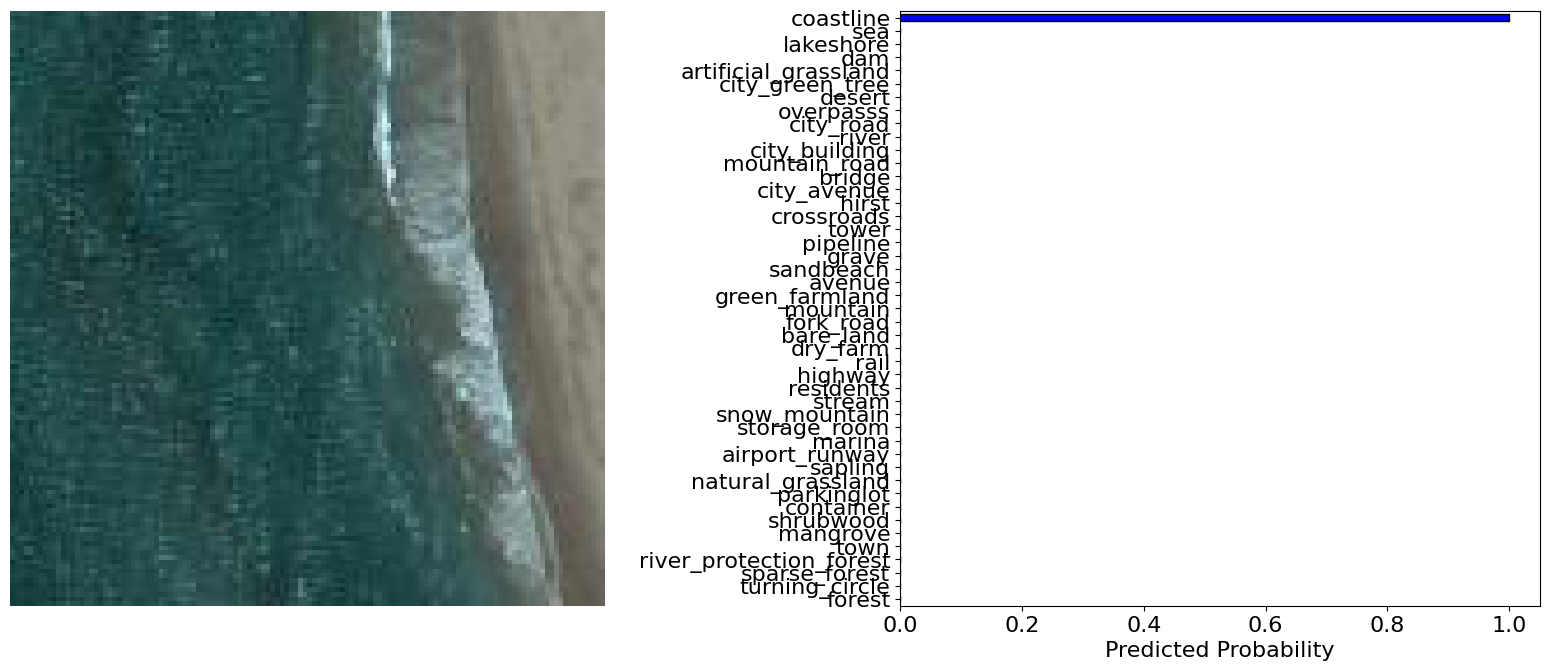

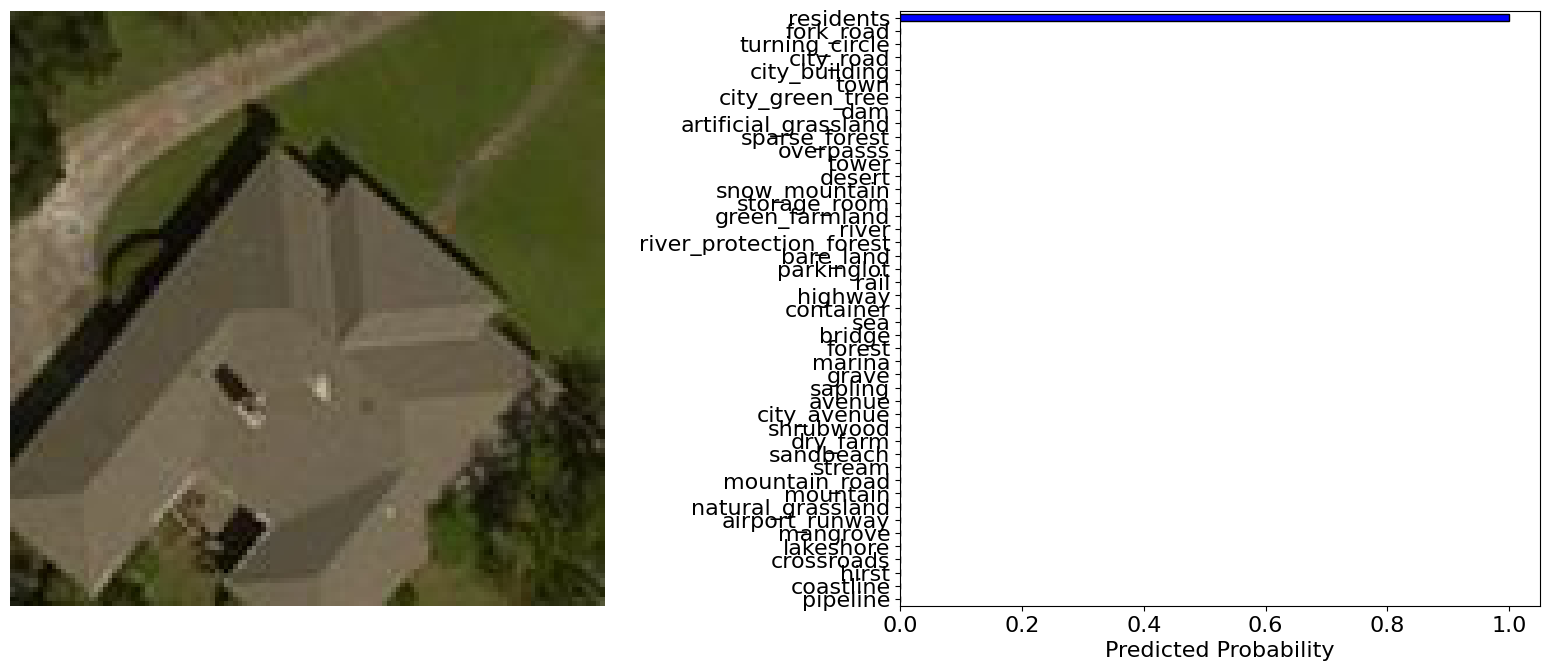

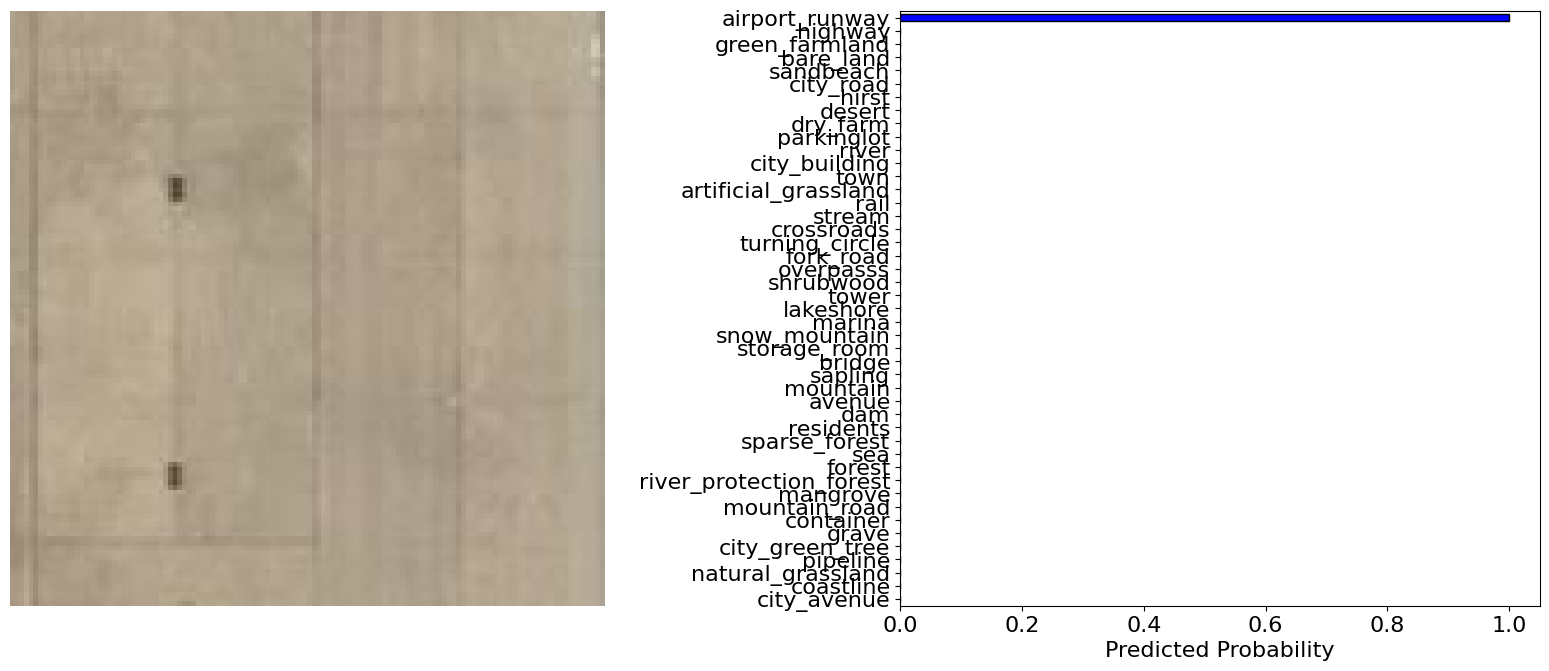

In [8]:
labels = ["airport_runway","artificial_grassland","avenue","bare_land","bridge","city_avenue","city_building",
          "city_green_tree","city_road", "coastline","container","crossroads","dam","desert","dry_farm","forest",
          "fork_road","grave","green_farmland","highway", "hirst","lakeshore","mangrove","marina","mountain",
          "mountain_road","natural_grassland","overpasss","parkinglot","pipeline","rail","residents","river",
          "river_protection_forest","sandbeach","sapling","sea","shrubwood","snow_mountain","sparse_forest",
          "storage_room","stream","tower","town","turning_circle"]
transform = ResizeCenterCropToTensor()

model_path = "/home/dragik/data/FAIR_EO/experiments/RSI-CB128/checkpoint.pth.tar"
model.load_model(model_path)

image = image_loader('/home/dragik/data/FAIR_EO/RSI-CB128/coastline/coastline(34).tif')
fig = model.predict_image(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/RSI-CB128/residents/residents(1009).tif')
fig = model.predict_image(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/RSI-CB128/airport_runway/airport_runway(884).tif')
fig = model.predict_image(image, labels, transform)